# Descriptive Statistics, Inferential Statistics and Random Forest
**STAT3013 – Member 1 (TV1)**

This notebook studies the link between **patient experience** (HCAHPS survey scores) and the **30-day readmission rate of heart failure patients** in U.S. hospitals. It has three parts:

1. **Descriptive statistics** – what the data looks like and how the variables relate to each other
2. **Inferential statistics** – whether the differences between high- and low-readmission hospitals are statistically significant (Welch t-test, Chi-square test)
3. **Random Forest** – predicting which hospitals belong to the high-readmission group from their HCAHPS scores

**Data:** `STAT3013_final_model_data.csv` – 2,850 hospitals with complete data, built from two CMS Provider Data Catalog datasets (HCAHPS – Hospital and Unplanned Hospital Visits – Hospital) merged on `Facility ID`.

| Role | Variable | Description |
| --- | --- | --- |
| Inputs | 8 HCAHPS linear mean scores (0–100) | See the data dictionary in Section 1.1 |
| Regression target | `READM_30_HF` | Heart failure 30-day readmission rate (%) |
| Classification target | `READM_HF_High` | 1 if `READM_30_HF` > 21.3, else 0. The cut-off 21.3 is the median of the **training set only**, so no information from the test set leaks into the labels |
| Fixed split | `Split` | 2,280 training / 570 test hospitals (`random_state = 42`), shared by every model of the group so results are comparable |

**To run:** keep `STAT3013_final_model_data.csv` and `prepare_split_and_standardize.py` in the same folder as this notebook, then run all cells (about 10 minutes, mostly hyper-parameter tuning).

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Shared helpers used by every model of the group: same data, same split, same evaluation
from prepare_split_and_standardize import load_data, evaluate, FEATURES, TARGET_CLASS, TARGET_RATE

sns.set_theme(style="whitegrid", font_scale=0.9)
FIG = "figures/"                      # all figures and result tables are saved here
os.makedirs(FIG, exist_ok=True)

# Facility ID must be read as text, otherwise leading zeros are lost (010001 -> 10001)
df = pd.read_csv("STAT3013_final_model_data.csv", dtype={"Facility ID": str})
df["Group"] = df[TARGET_CLASS].map({0: "Low", 1: "High"})
print("Rows x columns:", df.shape)
print("Split:", df["Split"].value_counts().to_dict(), "| share of High-readmission hospitals:", round(df[TARGET_CLASS].mean(), 3))

Rows x columns: (2850, 17)
Split: {'train': 2280, 'test': 570} | share of High-readmission hospitals: 0.48


## 1. Descriptive statistics

The first step is to understand the data before building any model. This part uses all 2,850 hospitals because it only describes the data; no model is trained here.

### 1.1 Data dictionary

In [2]:
dictionary = pd.DataFrame([
    ("Facility ID", "Identifier", "CMS Certification Number (6 characters), merge key", "Both"),
    ("Facility_Name / State", "Identifier", "Hospital name and U.S. state", "Both"),
    ("Nurse_Communication", "Input", "H_COMP_1_LINEAR_SCORE – nurses communicated well", "HCAHPS"),
    ("Doctor_Communication", "Input", "H_COMP_2_LINEAR_SCORE – doctors communicated well", "HCAHPS"),
    ("Medication_Communication", "Input", "H_COMP_5_LINEAR_SCORE – staff explained medicines", "HCAHPS"),
    ("Discharge_Information", "Input", "H_COMP_6_LINEAR_SCORE – patients got discharge information", "HCAHPS"),
    ("Cleanliness", "Input", "H_CLEAN_LINEAR_SCORE – room and bathroom were clean", "HCAHPS"),
    ("Quietness", "Input", "H_QUIET_LINEAR_SCORE – area around the room was quiet at night", "HCAHPS"),
    ("Overall_Hospital_Rating", "Input", "H_HSP_RATING_LINEAR_SCORE – overall rating of the hospital", "HCAHPS"),
    ("Recommend_Hospital", "Input", "H_RECMND_LINEAR_SCORE – would recommend the hospital", "HCAHPS"),
    ("READM_30_HF", "Target (regression)", "Heart failure 30-day readmission rate, %", "Unplanned Hospital Visits"),
    ("READM_HF_High", "Target (classification)", "1 if READM_30_HF > 21.3 (training-set median), else 0", "Derived"),
    ("Split", "Design", "train (2,280) / test (570), random_state = 42", "Derived"),
    ("Start_Date / End_Date", "Period", "Readmission measurement period (07/2023 – 06/2025)", "Unplanned Hospital Visits"),
], columns=["Variable", "Role", "Definition", "Source"])
dictionary.to_csv(FIG + "table_data_dictionary.csv", index=False)
print(dictionary.to_string(index=False))

                Variable                    Role                                                     Definition                    Source
             Facility ID              Identifier             CMS Certification Number (6 characters), merge key                      Both
   Facility_Name / State              Identifier                                   Hospital name and U.S. state                      Both
     Nurse_Communication                   Input               H_COMP_1_LINEAR_SCORE – nurses communicated well                    HCAHPS
    Doctor_Communication                   Input              H_COMP_2_LINEAR_SCORE – doctors communicated well                    HCAHPS
Medication_Communication                   Input              H_COMP_5_LINEAR_SCORE – staff explained medicines                    HCAHPS
   Discharge_Information                   Input     H_COMP_6_LINEAR_SCORE – patients got discharge information                    HCAHPS
             Cleanliness          

HCAHPS linear mean scores summarise all survey answers of a hospital on a 0–100 scale; a higher score means a better patient experience. The HCAHPS period is 10/2024 – 09/2025 and the readmission period is 07/2023 – 06/2025, so the two measures overlap but are not identical. The analysis is at **hospital level**, not patient level.

### 1.2 Summary statistics and distributions

In [3]:
cols = FEATURES + [TARGET_RATE]
desc = df[cols].describe().T
desc["variance"] = df[cols].var()
desc["skewness"] = df[cols].skew()
desc["kurtosis"] = df[cols].kurt()          # excess kurtosis: 0 for a normal distribution
desc = desc[["count", "mean", "std", "variance", "min", "25%", "50%", "75%", "max", "skewness", "kurtosis"]].round(2)
desc.to_csv(FIG + "table_descriptive.csv")
print(desc.to_string())

                           count   mean   std  variance   min   25%   50%   75%    max  skewness  kurtosis
Nurse_Communication       2850.0  91.06  2.51      6.31  74.0  90.0  91.0  93.0  100.0     -0.68      1.95
Doctor_Communication      2850.0  90.39  2.60      6.74  75.0  89.0  91.0  92.0  100.0     -0.50      1.87
Medication_Communication  2850.0  76.40  4.40     19.34  57.0  74.0  76.0  79.0   95.0      0.04      0.70
Discharge_Information     2850.0  85.31  3.93     15.44  64.0  83.0  86.0  88.0  100.0     -0.82      1.86
Cleanliness               2850.0  86.30  4.40     19.36  70.0  84.0  87.0  89.0   99.0     -0.34      0.20
Quietness                 2850.0  80.63  5.38     28.99  56.0  77.0  81.0  84.0   98.0     -0.55      0.33
Overall_Hospital_Rating   2850.0  87.50  3.50     12.27  69.0  86.0  88.0  90.0   98.0     -0.72      1.61
Recommend_Hospital        2850.0  86.55  4.63     21.41  61.0  84.0  87.0  90.0   98.0     -0.80      1.51
READM_30_HF               2850.0  21.

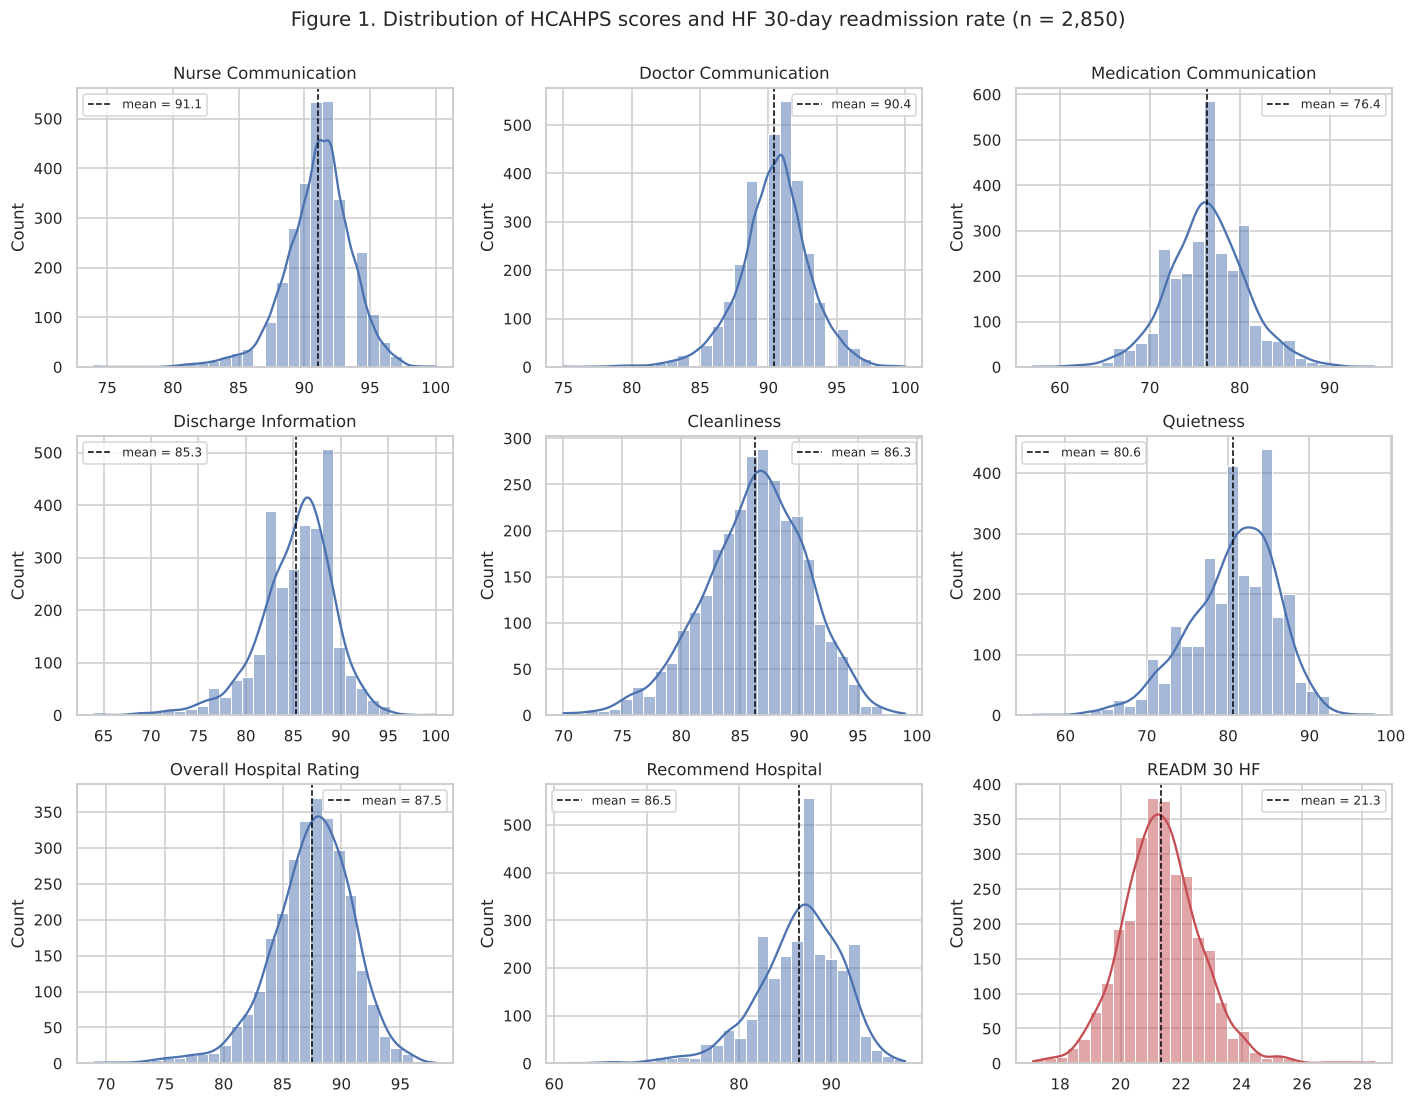

In [4]:
# Figure 1 – histogram with a kernel density curve for every variable
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], bins=30, kde=True, ax=ax, color="#4C72B0" if c != TARGET_RATE else "#C44E52")
    ax.axvline(df[c].mean(), color="black", ls="--", lw=1, label=f"mean = {df[c].mean():.1f}")
    ax.set_title(c.replace("_", " ")); ax.set_xlabel(""); ax.legend(fontsize=8)
fig.suptitle("Figure 1. Distribution of HCAHPS scores and HF 30-day readmission rate (n = 2,850)", y=1.0)
fig.tight_layout()
fig.savefig(FIG + "fig1_histograms.png", dpi=200, bbox_inches="tight")
plt.show()

Number of outliers by the IQR rule:
Nurse_Communication         83
Doctor_Communication        83
Medication_Communication    94
Discharge_Information       64
Cleanliness                 82
Quietness                   39
Overall_Hospital_Rating     69
Recommend_Hospital          53
READM_30_HF                 53


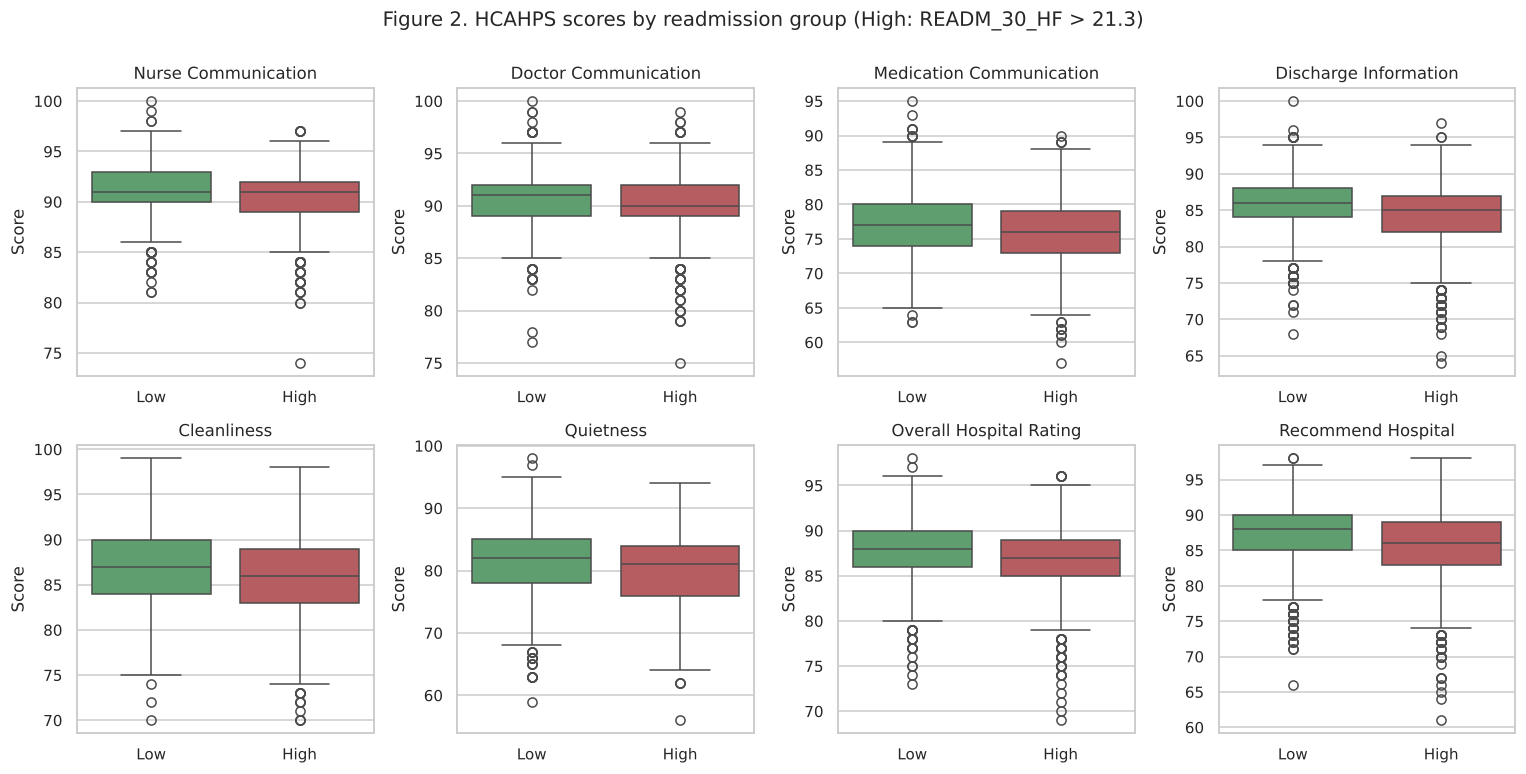

In [5]:
# Figure 2 – boxplots of each HCAHPS score for the Low and High readmission groups
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, c in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x="Group", y=c, order=["Low", "High"], hue="Group",
                palette={"Low": "#55A868", "High": "#C44E52"}, ax=ax, legend=False)
    ax.set_title(c.replace("_", " ")); ax.set_xlabel(""); ax.set_ylabel("Score")
fig.suptitle("Figure 2. HCAHPS scores by readmission group (High: READM_30_HF > 21.3)", y=1.0)
fig.tight_layout()
fig.savefig(FIG + "fig2_boxplots_by_group.png", dpi=200, bbox_inches="tight")
plt.show()

# Outlier check with the IQR rule. Outliers are reported, not removed: they are real hospital scores
q1, q3 = df[cols].quantile(0.25), df[cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[cols] < q1 - 1.5 * iqr) | (df[cols] > q3 + 1.5 * iqr)).sum()
outliers.rename("n_outliers_IQR").to_csv(FIG + "table_outliers_iqr.csv")
print("Number of outliers by the IQR rule:\n" + outliers.to_string())

Correlation with READM_30_HF:
Recommend_Hospital         -0.203
Discharge_Information      -0.202
Overall_Hospital_Rating    -0.175
Doctor_Communication       -0.139
Nurse_Communication        -0.129
Medication_Communication   -0.127
Quietness                  -0.090
Cleanliness                -0.065


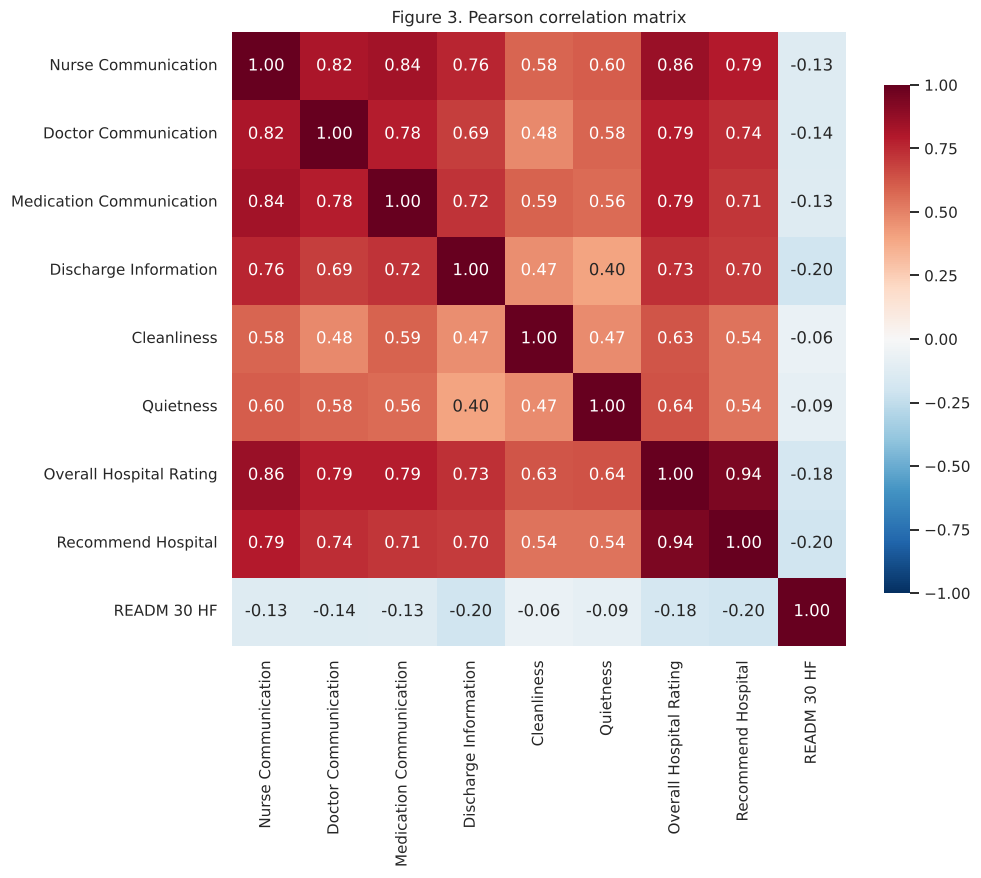

In [6]:
# Figure 3 – Pearson correlation matrix
corr = df[cols].corr()
corr.round(3).to_csv(FIG + "table_correlation.csv")
labels = [c.replace("_", " ") for c in cols]
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax, xticklabels=labels, yticklabels=labels)
ax.set_title("Figure 3. Pearson correlation matrix")
fig.savefig(FIG + "fig3_correlation_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()
print("Correlation with READM_30_HF:\n" + corr[TARGET_RATE].drop(TARGET_RATE).sort_values().round(3).to_string())

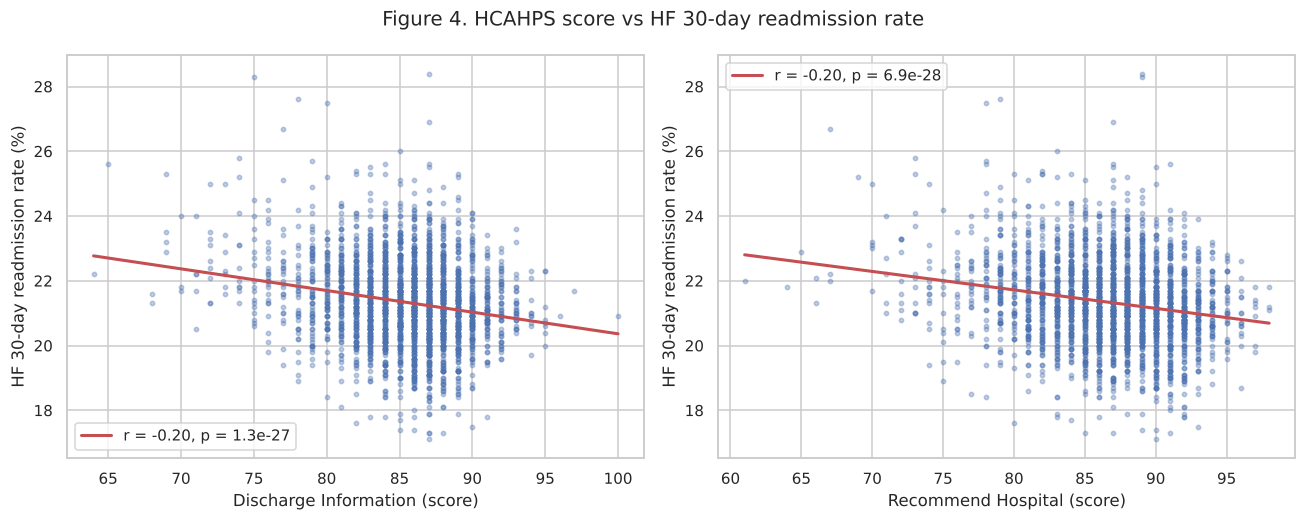

In [7]:
# Figure 4 – scatter plots of the two scores most correlated with the readmission rate
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, c in zip(axes, ["Discharge_Information", "Recommend_Hospital"]):
    r, p = stats.pearsonr(df[c], df[TARGET_RATE])
    ax.scatter(df[c], df[TARGET_RATE], s=8, alpha=0.35, color="#4C72B0")
    b1, b0 = np.polyfit(df[c], df[TARGET_RATE], 1)          # least-squares line
    xs = np.linspace(df[c].min(), df[c].max(), 100)
    ax.plot(xs, b0 + b1 * xs, color="#C44E52", lw=2, label=f"r = {r:.2f}, p = {p:.1e}")
    ax.set_xlabel(c.replace("_", " ") + " (score)"); ax.set_ylabel("HF 30-day readmission rate (%)")
    ax.legend()
fig.suptitle("Figure 4. HCAHPS score vs HF 30-day readmission rate")
fig.tight_layout()
fig.savefig(FIG + "fig4_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

### 1.3 Findings

- **HCAHPS scores are high overall.** Means range from 76 to 91 points, and most distributions are slightly left-skewed (skewness −0.82 to 0.04): most hospitals are rated well and only a few score low. Medication communication has the lowest mean (76.4) and quietness varies most between hospitals (SD 5.4).
- **Readmission rate.** `READM_30_HF` has a mean of 21.35% (SD 1.30), ranges from 17.1% to 28.4%, and is close to normal with a slight right skew (0.37).
- **Outliers.** Each variable has 39–94 values outside the IQR fences. They are real hospital results, not data-entry errors, so they are **kept**.
- **Correlation with readmission is negative but weak.** Hospitals with better patient experience tend to have lower readmission. The strongest links are with recommending the hospital and discharge information (r = −0.20), the weakest with cleanliness (r = −0.07).
- **HCAHPS scores are strongly correlated with each other.** Overall rating and recommend-the-hospital have r = 0.94, so they measure almost the same thing. This multicollinearity matters when the importance of single variables is interpreted.

---

## 2. Inferential statistics

The descriptive part shows that high-readmission hospitals score slightly lower. This part tests whether that difference is real or could be due to chance.

### 2.1 Welch two-sample t-test: do HCAHPS scores differ between the High and Low readmission groups?

For each of the 8 HCAHPS scores:
- H0: μ_High = μ_Low (the two groups have the same mean score)
- H1: μ_High ≠ μ_Low
- Significance level α = 0.05

$$t = \frac{\bar{x}_{High} - \bar{x}_{Low}}{\sqrt{s^2_{High}/n_{High} + s^2_{Low}/n_{Low}}}$$

Method choices:
- **Welch's t-test** does not assume equal variances. Levene's test is reported alongside and shows unequal variances for most scores.
- **Bonferroni correction:** testing 8 scores at once raises the chance of a false positive, so every p-value is multiplied by 8.
- **Normality:** each group has more than 1,300 hospitals, so by the Central Limit Theorem the sample means are approximately normal.
- **Cohen's d** measures the size of the difference (0.2 small, 0.5 medium, 0.8 large). A p-value only says whether a difference exists, not how large it is.

In [8]:
rows = []
hi, lo = df[df[TARGET_CLASS] == 1], df[df[TARGET_CLASS] == 0]
for c in FEATURES:
    t, p = stats.ttest_ind(hi[c], lo[c], equal_var=False)            # Welch's t-test
    lev_p = stats.levene(hi[c], lo[c]).pvalue                          # equal-variance check
    pooled_sd = np.sqrt(((len(hi) - 1) * hi[c].var() + (len(lo) - 1) * lo[c].var()) / (len(hi) + len(lo) - 2))
    rows.append({"Variable": c, "Mean_High": hi[c].mean(), "Mean_Low": lo[c].mean(),
                 "Diff": hi[c].mean() - lo[c].mean(), "t": t, "p_value": p,
                 "p_Bonferroni": min(p * len(FEATURES), 1.0), "Levene_p": lev_p,
                 "Cohen_d": (hi[c].mean() - lo[c].mean()) / pooled_sd})
ttab = pd.DataFrame(rows)
ttab["Reject_H0"] = np.where(ttab["p_Bonferroni"] < 0.05, "Yes", "No")
ttab.to_csv(FIG + "table_ttest.csv", index=False)
print(f"n_High = {len(hi)}, n_Low = {len(lo)}")
with pd.option_context("display.float_format", lambda v: f"{v:.4g}"):
    print(ttab.to_string(index=False))

n_High = 1368, n_Low = 1482
                Variable  Mean_High  Mean_Low    Diff      t   p_value  p_Bonferroni  Levene_p  Cohen_d Reject_H0
     Nurse_Communication      90.76     91.34 -0.5809 -6.175 7.583e-10     6.066e-09   0.01021  -0.2327       Yes
    Doctor_Communication      90.04     90.72  -0.677 -6.982 3.641e-12     2.913e-11  0.002624   -0.263       Yes
Medication_Communication      75.86      76.9  -1.036 -6.318 3.078e-10     2.462e-09    0.4555  -0.2372       Yes
   Discharge_Information      84.61     85.95  -1.339 -9.155 1.057e-19     8.458e-19 5.168e-07  -0.3458       Yes
             Cleanliness      86.04     86.53 -0.4887 -2.963  0.003074       0.02459    0.9058  -0.1112       Yes
               Quietness      80.16     81.07 -0.9131 -4.521 6.423e-06     5.138e-05 1.017e-05  -0.1702       Yes
 Overall_Hospital_Rating      86.95     88.01  -1.067 -8.176 4.452e-16     3.562e-15 0.0002206  -0.3082       Yes
      Recommend_Hospital      85.72     87.31  -1.585 -9.218

### 2.2 Chi-square test of independence: is the recommendation level related to the readmission group?

Hospitals are split into four equal groups by their `Recommend_Hospital` score (Q1 lowest to Q4 highest; tied scores are ordered by row so the groups have equal size). The quartiles are then cross-tabulated with `READM_HF_High`.
- H0: recommendation quartile and readmission group are independent
- H1: the two variables are associated
- Significance level α = 0.05; condition: every expected frequency ≥ 5
- Strength of association: Cramér's V (0 = none, 1 = perfect)

$$\chi^2 = \sum_{i}\frac{(O_i - E_i)^2}{E_i}, \qquad V = \sqrt{\frac{\chi^2}{n\,(\min(r, c) - 1)}}$$

Observed frequencies:
Group               Low  High
Recommend_Quartile           
Q1 (lowest)         292   421
Q2                  364   348
Q3                  384   328
Q4 (highest)        442   271

Share of High-readmission hospitals by quartile:
Recommend_Quartile
Q1 (lowest)     0.590
Q2              0.489
Q3              0.461
Q4 (highest)    0.380

chi2 = 64.66, dof = 3, p = 5.94e-14, Cramer's V = 0.151
Smallest expected frequency: 341.8


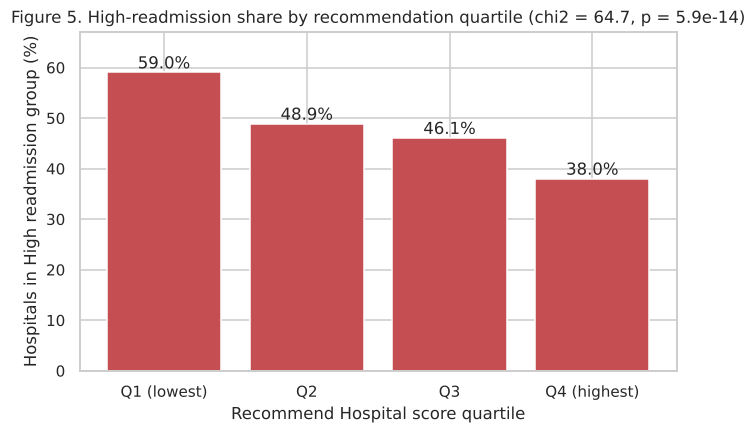

In [9]:
df["Recommend_Quartile"] = pd.qcut(df["Recommend_Hospital"].rank(method="first"), 4,
                                   labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
ct = pd.crosstab(df["Recommend_Quartile"], df["Group"])[["Low", "High"]]
chi2, p, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print("Observed frequencies:\n" + ct.to_string())
print("\nShare of High-readmission hospitals by quartile:\n" + (ct["High"] / ct.sum(axis=1)).round(3).to_string())
print(f"\nchi2 = {chi2:.2f}, dof = {dof}, p = {p:.2e}, Cramer's V = {cramers_v:.3f}")
print("Smallest expected frequency:", round(expected.min(), 1))
ct.to_csv(FIG + "table_chisquare_contingency.csv")
pd.DataFrame({"chi2": [chi2], "dof": [dof], "p_value": [p], "cramers_v": [cramers_v],
              "min_expected": [expected.min()]}).to_csv(FIG + "table_chisquare.csv", index=False)

# Figure 5 – share of High-readmission hospitals in each recommendation quartile
share = (ct["High"] / ct.sum(axis=1)) * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(share.index.astype(str), share.values, color="#C44E52")
for i, v in enumerate(share.values):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
ax.set_ylabel("Hospitals in High readmission group (%)"); ax.set_xlabel("Recommend Hospital score quartile")
ax.set_ylim(0, max(share.values) + 8)
ax.set_title(f"Figure 5. High-readmission share by recommendation quartile (chi2 = {chi2:.1f}, p = {p:.1e})")
fig.savefig(FIG + "fig5_chisquare_quartiles.png", dpi=200, bbox_inches="tight")
plt.show()

### 2.3 Findings

- **t-test: H0 is rejected for all 8 scores, also after Bonferroni correction.** High-readmission hospitals (n = 1,368) always score lower than low-readmission hospitals (n = 1,482). The largest gaps are in recommending the hospital (−1.58 points, d = −0.35) and discharge information (−1.34 points, d = −0.35); the smallest is in cleanliness (−0.49 points, d = −0.11).
- **The differences are real but small.** Every |Cohen's d| is at most 0.35. The large sample detects even small differences, but the two groups overlap heavily, so a model that uses only these scores will find it hard to separate them.
- **Chi-square: χ² = 64.66, df = 3, p = 5.9 × 10⁻¹⁴, so H0 is rejected.** The share of high-readmission hospitals falls steadily from 59.0% in the lowest recommendation quartile to 38.0% in the highest. Cramér's V = 0.15 indicates a weak association. The smallest expected frequency is 341.8, so the test condition holds.

---

## 3. Random Forest

The tests show that HCAHPS scores are related to readmission. The next question is whether they can **predict** which hospitals fall in the high-readmission group.

**How Random Forest works**
- A Random Forest combines many decision trees (bagging). Each tree learns from a bootstrap sample (random sample with replacement) of the training data, and at every split it considers only a random subset of the variables (`max_features`).
- The final prediction is the average class probability of all trees, which makes the model far more stable than a single tree.
- Each tree chooses the split that makes the child nodes as pure as possible, measured by the Gini impurity, where p_k is the share of class k in node t:

$$Gini(t) = 1 - \sum_{k} p_k^2$$

- Random Forest does not need feature scaling, because each split only compares one variable with a threshold.

**Evaluation protocol** (the same for every classifier of the group)
- **Cross-validation on the training set:** `RepeatedStratifiedKFold`, 5 folds × 10 repeats = 50 evaluations, scored by ROC-AUC. ROC-AUC is the probability that the model ranks a random high-readmission hospital above a random low-readmission one (0.5 = random guessing, 1.0 = perfect).
- **Test set:** used only once, for the final model, through the shared `evaluate()` function (Accuracy, Precision, Recall = sensitivity, F1, ROC-AUC, confusion matrix).

### 3.1 Baseline with default settings

In [10]:
import time
import joblib
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import roc_auc_score

X_train, X_test, y_train, y_test = load_data()          # fixed split from the shared file
CV_FINAL = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

rf_base = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)   # default hyper-parameters
base_cv = cross_val_score(rf_base, X_train, y_train, cv=CV_FINAL, scoring="roc_auc")
print(f"Baseline CV ROC-AUC (5x10) = {base_cv.mean():.4f} ± {base_cv.std():.4f}")

Train: (2280, 8) | Test: (570, 8)
Baseline CV ROC-AUC (5x10) = 0.5677 ± 0.0199


### 3.2 Hyper-parameter tuning

A grid of 48 combinations of three hyper-parameters is searched:
- `max_depth` – maximum depth of each tree (None = unlimited). Deeper trees can memorise noise.
- `min_samples_leaf` – minimum number of hospitals in a leaf. Larger values give smoother trees and less overfitting.
- `max_features` – share of variables considered at each split.

To save time, the grid search uses 5 folds × 3 repeats. The best combination is then re-scored with the full 5 × 10 protocol. The complete grid is saved to `figures/table_rf_tuning_all.csv`.

In [11]:
grid = {
    "max_depth": [None, 4, 8, 12],
    "min_samples_leaf": [1, 10, 30, 60],
    "max_features": ["sqrt", 0.5, 1.0],
}
CV_SEARCH = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
t0 = time.time()
search = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), grid,
                      cv=CV_SEARCH, scoring="roc_auc", n_jobs=1)
search.fit(X_train, y_train)
res = pd.DataFrame(search.cv_results_)
res["params_str"] = res["params"].astype(str)
res["depth"] = res["params"].apply(lambda q: q["max_depth"])
res[["params_str", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").to_csv(FIG + "table_rf_tuning_all.csv", index=False)
top = res.sort_values("mean_test_score", ascending=False)[["params_str", "mean_test_score", "std_test_score"]].head(10)
top.to_csv(FIG + "table_rf_tuning_top10.csv", index=False)
print(f"Grid search time: {time.time() - t0:.0f}s")
print(top.to_string(index=False))
best_params = search.best_params_
print("Best params:", best_params)

Grid search time: 431s
                                                      params_str  mean_test_score  std_test_score
   {'max_depth': 4, 'max_features': 1.0, 'min_samples_leaf': 30}         0.605949        0.022813
   {'max_depth': 4, 'max_features': 1.0, 'min_samples_leaf': 10}         0.602923        0.024044
   {'max_depth': 4, 'max_features': 1.0, 'min_samples_leaf': 60}         0.602526        0.023216
    {'max_depth': 4, 'max_features': 1.0, 'min_samples_leaf': 1}         0.602473        0.021973
   {'max_depth': 8, 'max_features': 1.0, 'min_samples_leaf': 60}         0.602153        0.021661
{'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 60}         0.602068        0.021669
  {'max_depth': 12, 'max_features': 1.0, 'min_samples_leaf': 60}         0.602068        0.021669
   {'max_depth': 8, 'max_features': 1.0, 'min_samples_leaf': 30}         0.601310        0.019652
   {'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 30}         0.601182        0.0206

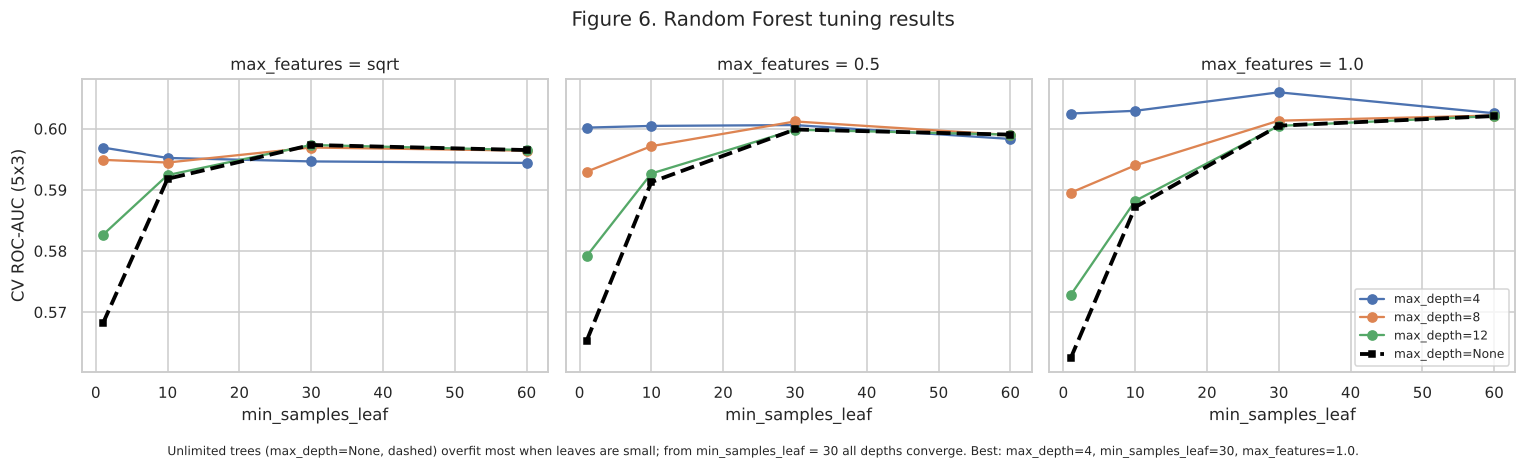

In [12]:
# Figure 6 – CV ROC-AUC of every grid combination
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, mf in zip(axes, grid["max_features"]):
    sub = res[res["params"].apply(lambda q: q["max_features"]) == mf]
    for depth in [4, 8, 12, None]:          # None drawn last (dashed) so it stays visible
        mask = sub["depth"].isna() if depth is None else (sub["depth"] == depth)
        s = sub[mask].sort_values("param_min_samples_leaf")
        style = dict(ls="--", lw=2.5, color="black", marker="s", ms=4) if depth is None else dict(marker="o")
        ax.plot(s["param_min_samples_leaf"].astype(int), s["mean_test_score"], label=f"max_depth={depth}", **style)
    ax.set_title(f"max_features = {mf}"); ax.set_xlabel("min_samples_leaf")
axes[0].set_ylabel("CV ROC-AUC (5x3)"); axes[-1].legend(fontsize=8)
fig.text(0.5, -0.03, "Unlimited trees (max_depth=None, dashed) overfit most when leaves are small; from min_samples_leaf = 30 all depths converge. Best: max_depth=4, min_samples_leaf=30, max_features=1.0.", ha="center", fontsize=8)
fig.suptitle("Figure 6. Random Forest tuning results")
fig.tight_layout()
fig.savefig(FIG + "fig6_rf_tuning.png", dpi=200, bbox_inches="tight")
plt.show()

The best `max_depth` (4) lies on the edge of the grid, so depths just around it (2–6) are checked with the other two hyper-parameters fixed at their best values.

In [13]:
depth_check = []
for d in [2, 3, 4, 5, 6]:
    params = {**best_params, "max_depth": d}
    s = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, **params),
                        X_train, y_train, cv=CV_SEARCH, scoring="roc_auc")
    depth_check.append({"max_depth": d, "cv_auc_mean": s.mean(), "cv_auc_std": s.std()})
depth_check = pd.DataFrame(depth_check)
depth_check.round(4).to_csv(FIG + "table_rf_depth_check.csv", index=False)
print(depth_check.round(4).to_string(index=False))
best_depth = int(depth_check.loc[depth_check["cv_auc_mean"].idxmax(), "max_depth"])
print("Best depth:", best_depth)
best_params["max_depth"] = best_depth

 max_depth  cv_auc_mean  cv_auc_std
         2       0.5971      0.0284
         3       0.6038      0.0240
         4       0.6059      0.0228
         5       0.6049      0.0213
         6       0.6035      0.0206
Best depth: 4


### 3.3 Final model: 5 × 10 cross-validation and test-set evaluation

In [14]:
rf = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1, **best_params)
final_cv = cross_val_score(rf, X_train, y_train, cv=CV_FINAL, scoring="roc_auc")
print("Final params:", best_params, "| n_estimators = 500")
print(f"Tuned RF CV ROC-AUC (5x10) = {final_cv.mean():.4f} ± {final_cv.std():.4f}")

rf.fit(X_train, y_train)
rf_base.fit(X_train, y_train)
print("\n--- Baseline RF on the test set ---")
res_base = evaluate(rf_base, X_test, y_test, "Random Forest baseline (default)")
print("\n--- Tuned RF on the test set ---")
res_rf = evaluate(rf, X_test, y_test, "Random Forest tuned")
train_auc = roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1])
print(f"\nTrain ROC-AUC (tuned) = {train_auc:.3f} – the gap to the test ROC-AUC shows the level of overfitting")

Final params: {'max_depth': 4, 'max_features': 1.0, 'min_samples_leaf': 30} | n_estimators = 500
Tuned RF CV ROC-AUC (5x10) = 0.6062 ± 0.0221

--- Baseline RF on the test set ---
Model        Random Forest baseline (default)
Accuracy                             0.540351
Precision                            0.497976
Recall                               0.471264
F1                                   0.484252
ROC-AUC                              0.566343
Confusion matrix [[TN, FP], [FN, TP]]:
 [[185 124]
 [138 123]]

--- Tuned RF on the test set ---
Model        Random Forest tuned
Accuracy                     0.6
Precision               0.582915
Recall                  0.444444
F1                      0.504348
ROC-AUC                 0.604694
Confusion matrix [[TN, FP], [FN, TP]]:
 [[226  83]
 [145 116]]

Train ROC-AUC (tuned) = 0.664 – the gap to the test ROC-AUC shows the level of overfitting


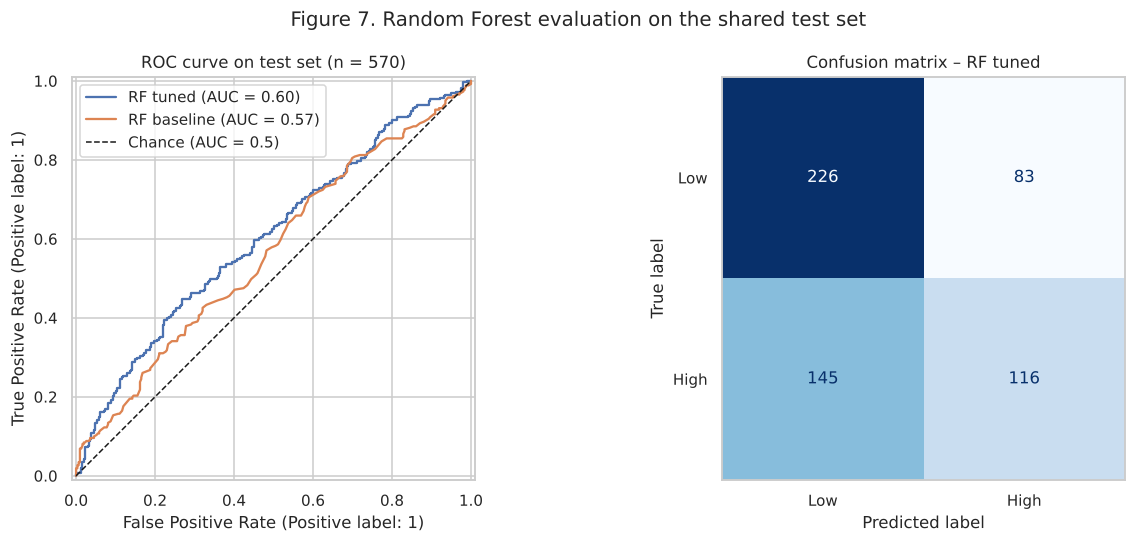

In [15]:
# Figure 7 – ROC curves and confusion matrix on the shared test set
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_estimator(rf, X_test, y_test, ax=axes[0], name="RF tuned")
RocCurveDisplay.from_estimator(rf_base, X_test, y_test, ax=axes[0], name="RF baseline")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.5)"); axes[0].legend()
axes[0].set_title("ROC curve on test set (n = 570)")
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, display_labels=["Low", "High"], cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Confusion matrix – RF tuned"); axes[1].grid(False)
fig.suptitle("Figure 7. Random Forest evaluation on the shared test set")
fig.tight_layout()
fig.savefig(FIG + "fig7_rf_roc_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

### 3.4 Feature importance

Two measures are used:
- **Impurity importance (MDI):** the average decrease in Gini impurity a variable brings, computed on the training data. It is fast but biased when variables are strongly correlated, as overall rating and recommend-the-hospital are here (r = 0.94).
- **Permutation importance:** the drop in test ROC-AUC when one variable is randomly shuffled, repeated 30 times. A bigger drop means a more important variable. This measure is more reliable for interpretation.

Per-hospital explanations with SHAP are produced in the SHAP notebook, using the saved `rf.pkl`.

                             MDI  Permutation_mean  Permutation_std
Recommend_Hospital        0.3652            0.0632           0.0230
Discharge_Information     0.2164            0.0269           0.0095
Quietness                 0.1309            0.0060           0.0050
Nurse_Communication       0.0539            0.0034           0.0042
Cleanliness               0.1331            0.0020           0.0074
Doctor_Communication      0.0155            0.0007           0.0009
Medication_Communication  0.0465           -0.0003           0.0013
Overall_Hospital_Rating   0.0385           -0.0007           0.0011


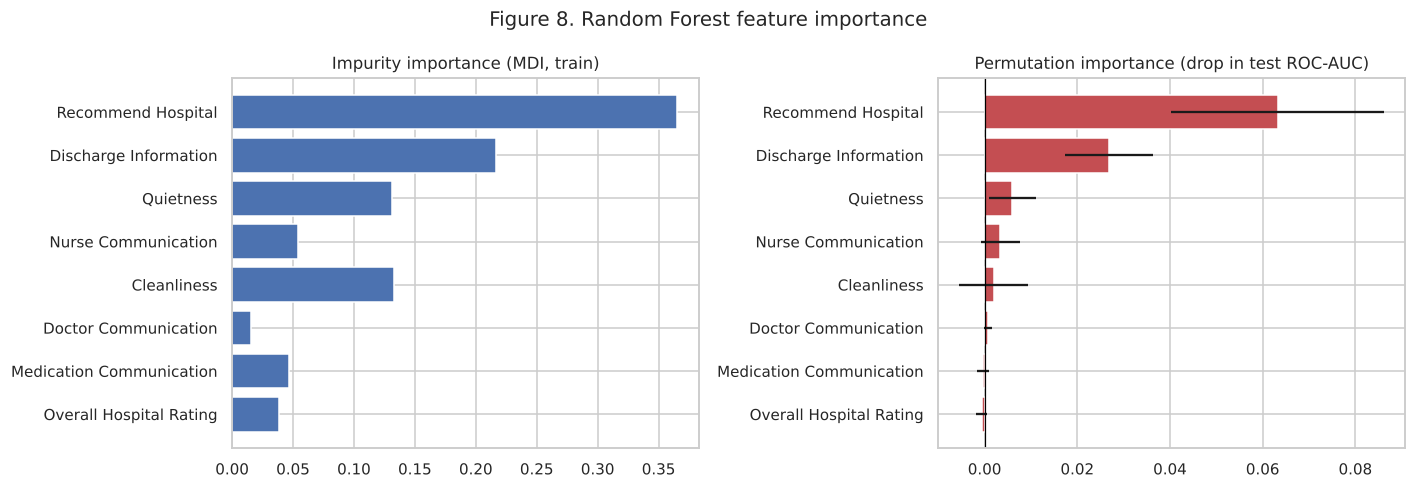

In [16]:
from sklearn.inspection import permutation_importance
mdi = pd.Series(rf.feature_importances_, index=FEATURES)
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=42, n_jobs=-1)
imp = pd.DataFrame({"MDI": mdi, "Permutation_mean": perm.importances_mean,
                    "Permutation_std": perm.importances_std}).sort_values("Permutation_mean")
imp.round(4).to_csv(FIG + "table_rf_importance.csv")
print(imp.sort_values("Permutation_mean", ascending=False).round(4).to_string())

# Figure 8 – both importance measures side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
labels = [c.replace("_", " ") for c in imp.index]
axes[0].barh(labels, imp["MDI"], color="#4C72B0"); axes[0].set_title("Impurity importance (MDI, train)")
axes[1].barh(labels, imp["Permutation_mean"], xerr=imp["Permutation_std"], color="#C44E52")
axes[1].axvline(0, color="black", lw=0.8); axes[1].set_title("Permutation importance (drop in test ROC-AUC)")
fig.suptitle("Figure 8. Random Forest feature importance")
fig.tight_layout()
fig.savefig(FIG + "fig8_rf_importance.png", dpi=200, bbox_inches="tight")
plt.show()

In [17]:
# Save the model (for SHAP) and the results (for the model comparison table)
joblib.dump(rf, "rf.pkl")
to_num = lambda d: {k: (float(v) if k != "Model" else v) for k, v in d.items()}
meta = {"model": "RandomForestClassifier", "params": rf.get_params(), "features": FEATURES,
        "target": TARGET_CLASS, "threshold_READM_30_HF": 21.3,
        "cv_protocol": "RepeatedStratifiedKFold 5x10 on train, ROC-AUC",
        "cv_auc_mean": float(final_cv.mean()), "cv_auc_std": float(final_cv.std()),
        "baseline_cv_auc_mean": float(base_cv.mean()), "baseline_cv_auc_std": float(base_cv.std()),
        "train_auc": float(train_auc),
        "test_baseline": to_num(res_base), "test": to_num(res_rf),
        "sklearn_version": sklearn.__version__}
with open("rf_results.json", "w") as f:
    json.dump(meta, f, indent=2, default=str)
pd.DataFrame([res_base, res_rf]).round(3).to_csv(FIG + "table_rf_test_results.csv", index=False)
print("Saved rf.pkl and rf_results.json (scikit-learn", sklearn.__version__ + ")")
check = joblib.load("rf.pkl")
print("Reload check – identical predictions:", bool((check.predict(X_test) == rf.predict(X_test)).all()))

Saved rf.pkl and rf_results.json (scikit-learn 1.9.1)
Reload check – identical predictions: True


## 4. Conclusions

| Model | CV ROC-AUC (5×10) | Accuracy | Precision | Recall | F1 | Test ROC-AUC |
| --- | --- | --- | --- | --- | --- | --- |
| Random Forest, default settings | 0.568 ± 0.020 | 0.540 | 0.498 | 0.471 | 0.484 | 0.566 |
| **Random Forest, tuned** | **0.606 ± 0.022** | **0.600** | **0.583** | **0.444** | **0.504** | **0.605** |

Final hyper-parameters: 500 trees, `max_depth = 4`, `min_samples_leaf = 30`, `max_features = 1.0`. Confusion matrix on the test set: TN 226, FP 83, FN 145, TP 116.

- **Tuning reduces overfitting.** The default model grows unlimited trees that memorise noise, reaching a test ROC-AUC of only 0.566. Limiting depth and leaf size raises it to 0.605, and the train–test gap after tuning is small (0.664 vs 0.605).
- **Depth 4 is the best choice.** It sat on the edge of the grid, but depths 2, 3, 5 and 6 all scored lower (Section 3.2).
- **`max_features = 1.0` works best,** meaning every split considers all 8 variables. Only two variables carry most of the signal; with a small random subset many trees are forced to split on weak variables.
- **The two most important variables are recommending the hospital and discharge information,** consistent with the correlations and the tests. Overall rating adds almost nothing on its own because it duplicates the information in recommend-the-hospital (r = 0.94).
- **Predictive power is modest (ROC-AUC ≈ 0.60).** This matches the inferential results: the differences between the groups are real but small. Patient-experience scores explain only a small part of readmission; factors such as patients' comorbidities or post-discharge care are not in the data.
- **Many high-readmission hospitals are missed (recall 0.44).** For screening, the probability threshold could be lowered to catch more of them, at the cost of more false alarms.

**Outputs:** `rf.pkl` (final model), `rf_results.json` (all metrics), and every figure and table in `figures/`.